# How did Leicester win the 2015/16 Premier League?

Leicester City started the season as **5000–1 outsiders** and finished it as champions, 10 points clear.
This notebook uses StatsBomb event data for all 380 matches to break the title down into five questions:

1. **Were they really the best team, or lucky?** Points vs expected points (xPts) from shot quality
2. **How did they attack?** Possession, directness and counter-attacks
3. **How did they defend?** Shots and chance quality conceded, and how it changed over the season
4. **Who made it work?** Vardy, Mahrez, Kanté and the supporting cast
5. **Did squad stability matter?** Players used and line-up changes

Data: `data/processed/2_27/` built by `python -m football_analytics.data 2 27` and `python -m football_analytics.clean`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mplsoccer import Pitch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = ROOT.parent  # repo root: shared code (src/) and downloaded data (data/raw, data/processed)
DATA = REPO / "data" / "processed" / "2_27"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

events = pd.read_parquet(DATA / "events.parquet")
player_match = pd.read_parquet(DATA / "player_match.parquet")
players = pd.read_parquet(DATA / "player_season.parquet")
matches = pd.read_parquet(REPO / "data" / "raw" / "2_27" / "matches.parquet")

LEI = "Leicester City"
RIVALS = ["Arsenal", "Tottenham Hotspur", "Manchester City"]

# Chart style: every team grey, Leicester in one blue accent
BLUE, GREY, DARK = "#1F5FAD", "#B4B2A9", "#3D3D3A"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
SOURCE = "Data: StatsBomb Open Data, Premier League 2015/16"

def finish(fig, name, subtitle=None):
    if subtitle:
        fig.axes[0].annotate(subtitle, xy=(0, 1.01), xycoords="axes fraction", fontsize=9.5, color="#6B6A64")
    fig.text(0.01, -0.02, SOURCE, fontsize=8, color="#8A8880")
    fig.savefig(FIGS / f"{name}.png")
    plt.show()

shots = events[events["type"] == "Shot"].copy()
shots["xg"] = shots["shot_statsbomb_xg"].astype(float)
shots["goal"] = shots["shot_outcome"] == "Goal"
print(f"{len(matches)} matches, {len(events):,} player actions, {len(shots):,} shots")

380 matches, 1,305,608 player actions, 9,908 shots


## 1. Team-match table

One row per team per match: goals, xG for and against, and a possession proxy (share of the match's passes).

In [2]:
m = matches.assign(hs=matches["home_score"].astype(int), aw=matches["away_score"].astype(int))
rows = []
for r in m.itertuples():
    rows.append(dict(match_id=r.match_id, date=r.match_date, team=r.home_team, opp=r.away_team, gf=r.hs, ga=r.aw, home=True))
    rows.append(dict(match_id=r.match_id, date=r.match_date, team=r.away_team, opp=r.home_team, gf=r.aw, ga=r.hs, home=False))
tm = pd.DataFrame(rows)
tm["pts"] = np.select([tm.gf > tm.ga, tm.gf == tm.ga], [3, 1], 0)

xg_for = shots.groupby(["match_id", "team"])["xg"].sum().rename("xgf")
tm = tm.join(xg_for, on=["match_id", "team"]).fillna({"xgf": 0})
tm["xga"] = tm.groupby("match_id")["xgf"].transform("sum") - tm["xgf"]

passes = events[events["type"] == "Pass"].groupby(["match_id", "team"]).size().rename("passes")
tm = tm.join(passes, on=["match_id", "team"])
tm["possession"] = tm["passes"] / tm.groupby("match_id")["passes"].transform("sum")

tm = tm.sort_values(["team", "date"])
tm["game"] = tm.groupby("team").cumcount() + 1
tm.head()

,match_id,date,team,opp,gf,ga,home,pts,xgf,xga,passes,possession,game
756,3754128,2015-08-08,AFC Bournemouth,Aston Villa,0,1,True,0,1.249248,0.651935,604,0.581328,1
751,3754020,2015-08-17,AFC Bournemouth,Liverpool,0,1,False,0,0.789176,1.833528,425,0.450689,2
351,3754131,2015-08-22,AFC Bournemouth,West Ham United,4,3,False,3,2.737927,1.695746,506,0.549403,3
96,3754023,2015-08-29,AFC Bournemouth,Leicester City,1,1,True,1,0.300446,0.828728,511,0.560922,4
299,3754315,2015-09-12,AFC Bournemouth,Norwich City,1,3,False,0,0.776673,1.319562,527,0.524900,5


## 2. Expected points: were Leicester the best team?

For every match, each shot is simulated 10,000 times as a goal with probability equal to its xG.
The share of simulations a team wins or draws gives its **expected points (xPts)**: the points its chances deserved on average.

In [3]:
rng = np.random.default_rng(42)
N_SIMS = 10_000
xpts = {}
for match_id, g in shots.groupby("match_id"):
    home, away = tm.loc[tm.match_id == match_id, "team"].tolist()
    sims = {}
    for team in (home, away):
        p = g.loc[g.team == team, "xg"].to_numpy()
        sims[team] = (rng.random((N_SIMS, len(p))) < p).sum(axis=1)
    for a, b in ((home, away), (away, home)):
        xpts[(match_id, a)] = (3 * (sims[a] > sims[b]) + (sims[a] == sims[b])).mean()
tm["xpts"] = [xpts[(r.match_id, r.team)] for r in tm.itertuples()]

table = (tm.groupby("team")
           .agg(Pts=("pts", "sum"), xPts=("xpts", "sum"), GF=("gf", "sum"), GA=("ga", "sum"),
                xGF=("xgf", "sum"), xGA=("xga", "sum"), possession=("possession", "mean"))
           .assign(GD=lambda d: d.GF - d.GA, overperformance=lambda d: d.Pts - d.xPts))
table = table.sort_values(["Pts", "GD"], ascending=False)
table["rank"] = range(1, 21)
table["xPts_rank"] = table["xPts"].rank(ascending=False).astype(int)
table.round(1)

,Pts,xPts,GF,GA,xGF,xGA,possession,GD,overperformance,rank,xPts_rank
team,,,,,,,,,,,
Leicester City,81,66.2,68,36,66.3,46.1,0.4,32,14.8,1,4
Arsenal,71,73.5,65,36,65.1,33.6,0.6,29,-2.5,2,1
Tottenham Hotspur,70,69.9,69,35,62.4,35.6,0.6,34,0.1,3,2
Manchester City,66,68.2,71,41,64.6,39.1,0.6,30,-2.2,4,3
Manchester United,66,54.7,49,35,42.2,38.5,0.6,14,11.3,5,8
Southampton,63,62.1,59,41,54.2,39.8,0.5,18,0.9,6,6
West Ham United,62,51.2,65,51,54.5,54.3,0.5,14,10.8,7,10
Liverpool,60,64.8,63,50,58.4,38.0,0.6,13,-4.8,8,5
Stoke City,51,44.4,41,55,40.4,55.2,0.5,-14,6.6,9,15


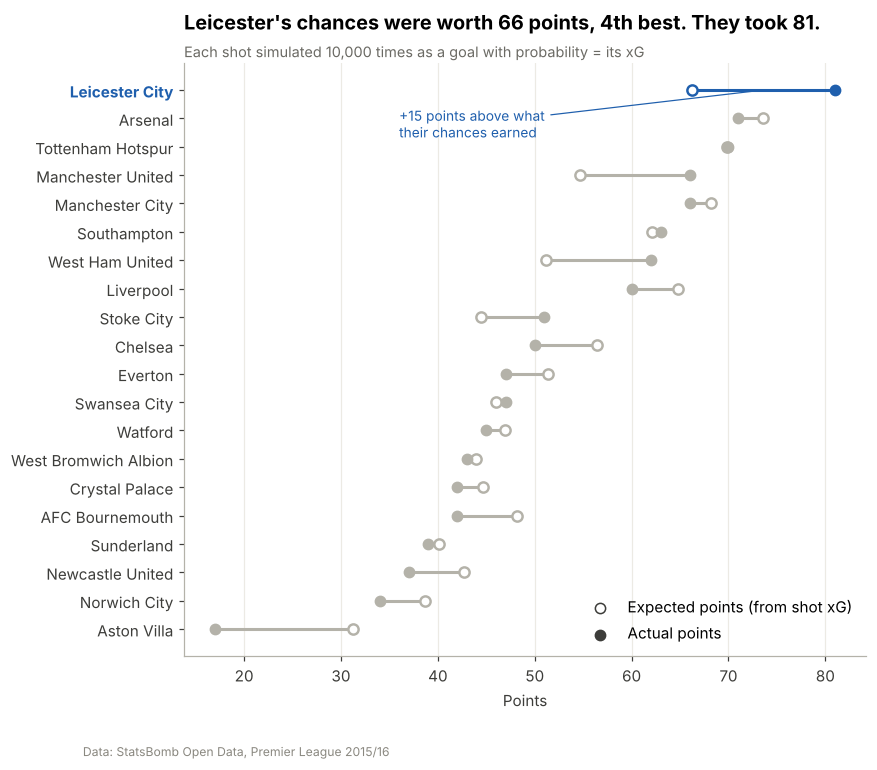

In [4]:
t = table.sort_values("Pts")
fig, ax = plt.subplots(figsize=(8, 7))
for i, (team, r) in enumerate(t.iterrows()):
    c = BLUE if team == LEI else GREY
    ax.plot([r.xPts, r.Pts], [i, i], color=c, lw=2, solid_capstyle="round", zorder=1)
    ax.scatter(r.xPts, i, s=45, facecolor="white", edgecolor=c, lw=1.6, zorder=2)
    ax.scatter(r.Pts, i, s=45, color=c, zorder=3)
ax.set_yticks(range(len(t)), t.index)
for lbl in ax.get_yticklabels():
    if lbl.get_text() == LEI:
        lbl.set_color(BLUE); lbl.set_fontweight("bold")
lei = table.loc[LEI]
ax.annotate(f"+{lei.overperformance:.0f} points above what\ntheir chances earned",
            xy=(lei.xPts + (lei.Pts - lei.xPts) / 2, len(t) - 1), xytext=(36, len(t) - 2.2),
            fontsize=9, color=BLUE, va="center", arrowprops=dict(arrowstyle="-", color=BLUE, lw=0.8))
ax.set_xlabel("Points")
ax.grid(axis="y", visible=False)
ax.scatter([], [], s=45, facecolor="white", edgecolor=DARK, label="Expected points (from shot xG)")
ax.scatter([], [], s=45, color=DARK, label="Actual points")
ax.legend(loc="lower right", frameon=False)
ax.set_title(f"Leicester's chances were worth {lei.xPts:.0f} points, 4th best. They took {lei.Pts:.0f}.", pad=22)
finish(fig, "01_points_vs_expected_points", "Each shot simulated 10,000 times as a goal with probability = its xG")

In [5]:
lei_games = tm[tm.team == LEI]
summary = pd.DataFrame({
    team: {
        "Wins": (g.pts == 3).sum(), "Draws": (g.pts == 1).sum(), "Losses": (g.pts == 0).sum(),
        "One-goal wins": ((g.gf - g.ga) == 1).sum(), "1-0 wins": ((g.gf == 1) & (g.ga == 0)).sum(),
        "Clean sheets": (g.ga == 0).sum(),
    }
    for team, g in tm[tm.team.isin([LEI] + RIVALS)].groupby("team")
})[[LEI] + RIVALS]
summary

,Leicester City,Arsenal,Tottenham Hotspur,Manchester City
Wins,23,20,19,19
Draws,12,11,13,9
Losses,3,7,6,10
One-goal wins,14,7,6,6
1-0 wins,7,3,3,2
Clean sheets,15,18,13,16


In [6]:
pens = shots[shots.shot_type == "Penalty"].groupby("team").agg(penalties=("goal", "size"), scored=("goal", "sum"))
np_xg = shots[shots.shot_type != "Penalty"].groupby("team")["xg"].sum().rename("non_penalty_xG")
pens.join(np_xg).sort_values("penalties", ascending=False).head(6).round(1)

,penalties,scored,non_penalty_xG
team,,,
Leicester City,13,10,56.1
Manchester City,8,5,58.3
Watford,7,6,38.6
Chelsea,5,4,49.7
West Bromwich Albion,5,1,34.7
Tottenham Hotspur,5,5,58.4


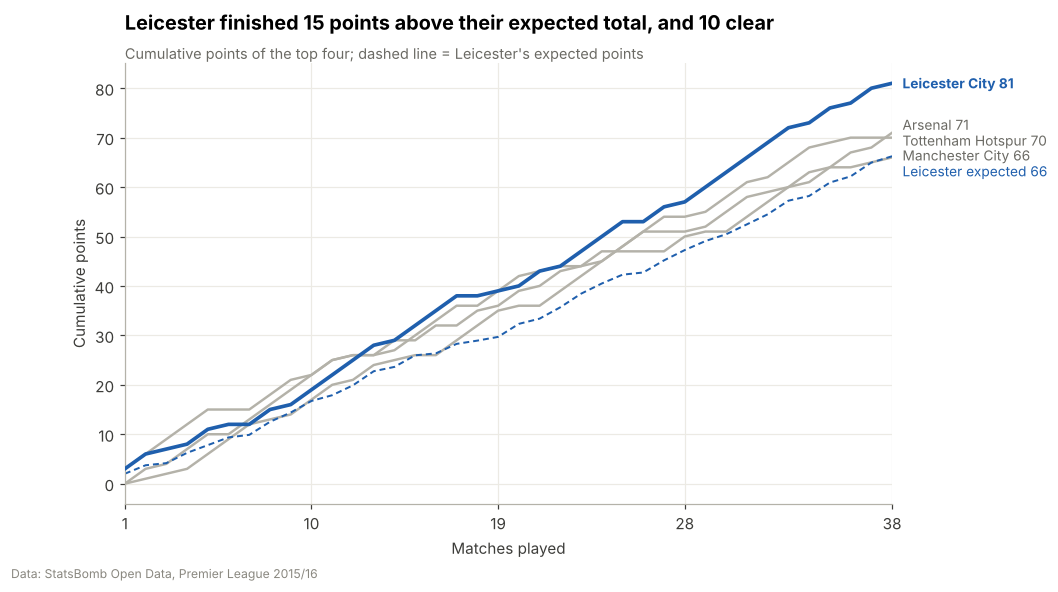

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.2))
for team, g in tm[tm.team.isin([LEI] + RIVALS)].groupby("team"):
    g = g.sort_values("game")
    lead = team == LEI
    ax.plot(g.game, g.pts.cumsum(), color=BLUE if lead else GREY, lw=2.4 if lead else 1.6, zorder=3 if lead else 2)
    ax.annotate(f"{team} {g.pts.sum()}", (38.5, {"Arsenal": 72.6, "Tottenham Hotspur": 69.4, "Manchester City": 66.4}.get(team, g.pts.sum())),
                va="center", fontsize=9, annotation_clip=False,
                color=BLUE if lead else "#6B6A64", fontweight="bold" if lead else "normal")
g = lei_games.sort_values("game")
ax.plot(g.game, g.xpts.cumsum(), color=BLUE, lw=1.3, ls=(0, (3, 2)), zorder=2)
ax.annotate(f"Leicester expected {g.xpts.sum():.0f}", (38.5, 63.2), va="center", fontsize=9,
            color=BLUE, annotation_clip=False)
ax.set_xlim(1, 38); ax.set_xticks([1, 10, 19, 28, 38])
ax.set_xlabel("Matches played"); ax.set_ylabel("Cumulative points")
ax.set_title(f"Leicester finished {g.pts.sum() - g.xpts.sum():.0f} points above their expected total, and 10 clear", pad=22)
finish(fig, "02_title_race", "Cumulative points of the top four; dashed line = Leicester's expected points")

## 3. How Leicester attacked: few passes, fast shots

For each shot, count the passes in that possession before the shot and the seconds since the possession began.

In [8]:
ev = events.assign(t=events.period * 10_000 + events.clock * 60)
poss_start = ev.groupby(["match_id", "possession"])["t"].min().rename("poss_start")
poss_passes = ev[ev.type == "Pass"].groupby(["match_id", "possession"]).size().rename("passes_before")

open_shots = shots[shots.shot_type != "Penalty"].join(poss_start, on=["match_id", "possession"])
open_shots = open_shots.join(passes_before := poss_passes, on=["match_id", "possession"]).fillna({"passes_before": 0})
open_shots["secs"] = open_shots.period * 10_000 + open_shots.clock * 60 - open_shots.poss_start

pass_events = events[(events.type == "Pass") & ~events.pass_type.isin(["Corner", "Throw-in", "Kick Off", "Free Kick", "Goal Kick"])]
style = pd.DataFrame({
    "possession": table.possession,
    "median_passes_before_shot": open_shots.groupby("team").passes_before.median(),
    "fast_shot_share": open_shots.groupby("team").secs.apply(lambda s: (s <= 15).mean()),
    "long_ball_share": pass_events.groupby("team").pass_length.apply(lambda s: (s.astype(float) >= 32).mean()),
    "pass_completion": pass_events.groupby("team").pass_outcome.apply(lambda s: s.isna().mean()),
    "counter_xg_share": open_shots.groupby("team").apply(lambda g: g.loc[g.play_pattern == "From Counter", "xg"].sum() / g.xg.sum(), include_groups=False),
    "np_xg_per_shot": open_shots.groupby("team").xg.mean(),
})
style.sort_values("fast_shot_share", ascending=False).round(3)

,possession,median_passes_before_shot,fast_shot_share,long_ball_share,pass_completion,counter_xg_share,np_xg_per_shot
team,,,,,,,
Leicester City,0.426,3.0,0.670,0.194,0.707,0.119,0.110
West Ham United,0.484,4.0,0.622,0.179,0.767,0.092,0.093
Crystal Palace,0.460,4.0,0.617,0.199,0.730,0.053,0.081
Sunderland,0.416,4.0,0.614,0.222,0.698,0.073,0.090
West Bromwich Albion,0.402,4.0,0.598,0.214,0.691,0.043,0.089
Southampton,0.495,4.0,0.579,0.185,0.756,0.077,0.098
Watford,0.451,4.0,0.578,0.185,0.723,0.059,0.087
Norwich City,0.465,5.0,0.534,0.185,0.728,0.026,0.090
Aston Villa,0.466,4.0,0.531,0.170,0.768,0.041,0.072


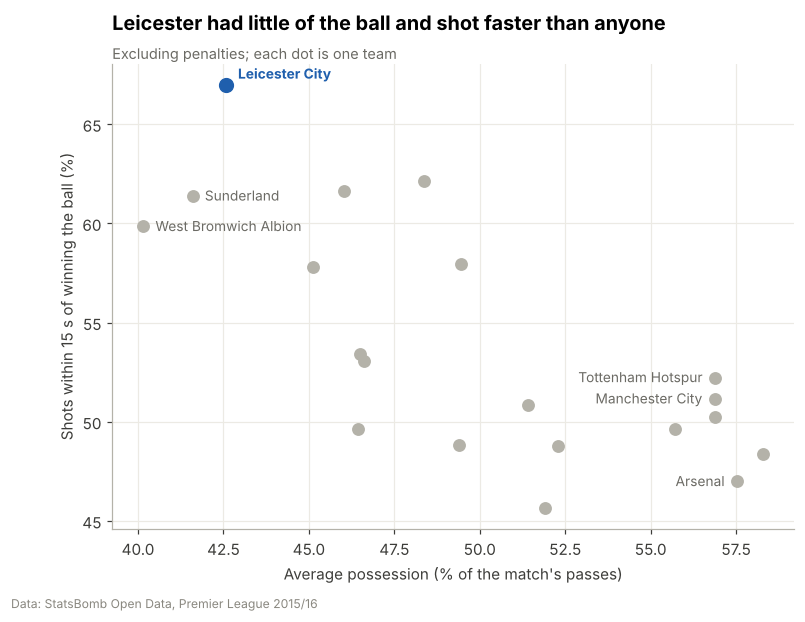

In [9]:
fig, ax = plt.subplots(figsize=(8, 5.5))
x, y = style.possession * 100, style.fast_shot_share * 100
others = style.index != LEI
ax.scatter(x[others], y[others], s=55, color=GREY, zorder=2)
ax.scatter(x[LEI], y[LEI], s=80, color=BLUE, zorder=3)
offsets = {LEI: (8, 4, "left"), "Arsenal": (-8, -3, "right"), "Tottenham Hotspur": (-8, -3, "right"),
           "Manchester City": (-8, -3, "right"), "West Bromwich Albion": (8, -3, "left"), "Sunderland": (8, -3, "left")}
for team, (dx, dy, ha) in offsets.items():
    ax.annotate(team, (x[team], y[team]), xytext=(dx, dy), textcoords="offset points", fontsize=9, ha=ha,
                color=BLUE if team == LEI else "#6B6A64", fontweight="bold" if team == LEI else "normal")
ax.set_xlabel("Average possession (% of the match's passes)")
ax.set_ylabel("Shots within 15 s of winning the ball (%)")
ax.set_title("Leicester had little of the ball and shot faster than anyone", pad=22)
finish(fig, "03_possession_vs_directness", "Excluding penalties; each dot is one team")

## 4. How Leicester defended

They faced plenty of shots, but mostly poor ones, and the defence tightened sharply in the second half of the season.

In [10]:
opp_of = tm.set_index(["match_id", "team"])["opp"]
shots_against = shots.assign(defending=[opp_of[(m_, t_)] for m_, t_ in zip(shots.match_id, shots.team)])
defence = shots_against.groupby("defending").agg(shots_against=("xg", "size"), xg_per_shot_against=("xg", "mean"))
defence = defence.join(table[["GA", "xGA"]])
defence.loc[[LEI] + RIVALS].round(3)

,shots_against,xg_per_shot_against,GA,xGA
defending,,,,
Leicester City,517,0.089,36,46.134
Arsenal,456,0.074,36,33.575
Tottenham Hotspur,428,0.083,35,35.561
Manchester City,343,0.114,41,39.059


In [11]:
lg = lei_games.sort_values("game")
halves = pd.DataFrame({
    half: {"Points": g.pts.sum(), "Expected points": round(g.xpts.sum(), 1),
           "Goals scored": g.gf.sum(), "xG for": round(g.xgf.sum(), 1),
           "Goals conceded": g.ga.sum(), "xG against": round(g.xga.sum(), 1),
           "Clean sheets": (g.ga == 0).sum()}
    for half, g in [("Matches 1-19", lg[lg.game <= 19]), ("Matches 20-38", lg[lg.game > 19])]
})
halves

,Matches 1-19,Matches 20-38
Points,39.0,42.0
Expected points,29.7,36.5
Goals scored,37.0,31.0
xG for,31.0,35.3
Goals conceded,25.0,11.0
xG against,25.9,20.2
Clean sheets,4.0,11.0


## 5. Where did the extra 15 points come from?

Compare goals with xG at both ends of the pitch. `goals_saved_vs_xG` = xG conceded − goals conceded (positive means fewer goals conceded than the chances allowed).
`np_finishing` = non-penalty goals − non-penalty xG.

In [12]:
np_goals = shots[shots.shot_type != "Penalty"].groupby("team").agg(np_goals=("goal", "sum"), np_xG=("xg", "sum"))
ends = table[["Pts", "xPts", "GA", "xGA"]].join(np_goals)
ends["np_finishing"] = ends.np_goals - ends.np_xG
ends["goals_saved_vs_xG"] = ends.xGA - ends.GA
ends.sort_values("goals_saved_vs_xG", ascending=False).round(1).head(8)

,Pts,xPts,GA,xGA,np_goals,np_xG,np_finishing,goals_saved_vs_xG
team,,,,,,,,
Leicester City,81,66.2,36,46.1,57,56.1,0.9,10.1
Manchester United,66,54.7,35,38.5,43,39.8,3.2,3.5
Watford,45,46.9,50,53.4,30,38.6,-8.6,3.4
West Ham United,62,51.2,51,54.3,60,51.4,8.6,3.3
Crystal Palace,42,44.7,51,52.8,34,38.5,-4.5,1.8
West Bromwich Albion,43,44.0,48,48.7,31,34.7,-3.7,0.7
Tottenham Hotspur,70,69.9,35,35.6,63,58.4,4.6,0.6
Stoke City,51,44.4,55,55.2,35,36.5,-1.5,0.2


## 6. Who made it work

Season totals for Leicester's regulars, plus how N'Golo Kanté's ball-winning compares with the rest of the league.

In [13]:
def per_player(mask, name):
    return events[mask].groupby("player_id").size().rename(name)

stats = players.set_index("player_id").join([
    shots.groupby("player_id").agg(goals=("goal", "sum"), xG=("xg", "sum"),
                                   penalties=("shot_type", lambda s: (s == "Penalty").sum())),
    shots[shots.shot_type != "Penalty"].groupby("player_id").agg(np_goals=("goal", "sum"), np_xG=("xg", "sum")),
    per_player(events.pass_goal_assist, "assists"),
    per_player(events.pass_shot_assist | events.pass_goal_assist, "chances_created"),
    per_player((events.type == "Duel") & (events.duel_type == "Tackle"), "tackles"),
    per_player(events.type == "Interception", "interceptions"),
]).fillna(0)
stats["tackles_int_p90"] = (stats.tackles + stats.interceptions) / stats.minutes * 90

cols = ["display_name", "position_group", "minutes", "goals", "penalties", "np_goals", "np_xG",
        "assists", "chances_created", "tackles", "interceptions"]
stats[stats.main_team == LEI].sort_values("minutes", ascending=False)[cols].head(11).round(1)

,display_name,position_group,minutes,goals,penalties,np_goals,np_xG,assists,chances_created,tackles,interceptions
player_id,,,,,,,,,,,
3813,Wes Morgan,Defender,3594,2.0,0.0,2.0,2.9,0.0,3.0,53.0,46.0
3815,Kasper Schmeichel,Goalkeeper,3594,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0
40123,Robert Huth,Defender,3313,3.0,0.0,3.0,2.6,0.0,1.0,37.0,46.0
10960,Jamie Vardy,Forward,3265,24.0,6.0,19.0,17.6,5.0,41.0,42.0,9.0
3961,N'Golo Kanté,Midfielder,3179,1.0,0.0,1.0,0.8,3.0,27.0,164.0,110.0
3662,Danny Drinkwater,Midfielder,3164,2.0,0.0,2.0,1.8,7.0,41.0,109.0,37.0
3814,Riyad Mahrez,Midfielder,3107,17.0,6.0,13.0,7.5,10.0,66.0,52.0,33.0
3812,Christian Fuchs,Defender,2845,0.0,0.0,0.0,1.0,4.0,47.0,101.0,73.0
3307,Marc Albrighton,Midfielder,2834,2.0,0.0,2.0,2.4,7.0,62.0,71.0,23.0


In [14]:
regulars = stats[(stats.minutes >= 1800) & (stats.position_group != "Goalkeeper")]
regulars.assign(tackles_plus_int=regulars.tackles + regulars.interceptions) \
    .sort_values("tackles_plus_int", ascending=False)[["display_name", "main_team", "tackles_plus_int", "tackles_int_p90"]] \
    .head(8).round(2)

,display_name,main_team,tackles_plus_int,tackles_int_p90
player_id,,,,
3961,N'Golo Kanté,Leicester City,274.0,7.76
3436,Idrissa Gueye,Aston Villa,233.0,6.55
3467,Erik Pieters,Stoke City,193.0,5.38
3277,Yohan Cabaye,Crystal Palace,191.0,6.20
3957,César Azpilicueta,Chelsea,187.0,5.01
3967,Claudio Yacob,West Bromwich Albion,175.0,5.33
4429,Yann M'Vila,Sunderland,174.0,4.69
3812,Christian Fuchs,Leicester City,174.0,5.50


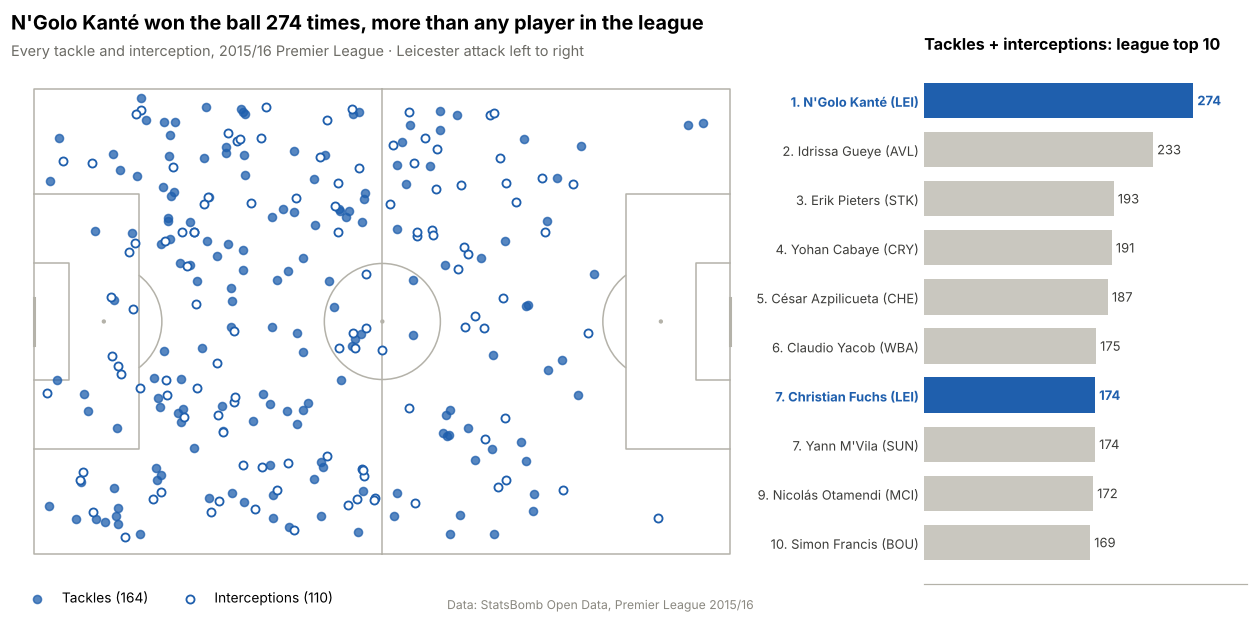

In [15]:
kante_id = stats.index[stats.display_name == "N'Golo Kanté"][0]
k = events[(events.player_id == kante_id) &
           (((events.type == "Duel") & (events.duel_type == "Tackle")) | (events.type == "Interception"))]
import sys; sys.path.insert(0, str(REPO / "src"))
from football_analytics.viz import leaderboard
of = stats[stats.position_group != "Goalkeeper"]
fig = plt.figure(figsize=(14.5, 6.2))
gs = fig.add_gridspec(1, 2, width_ratios=[2.3, 1], wspace=0.32)
ax, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
pitch = Pitch(pitch_type="statsbomb", line_color="#B4B2A9", linewidth=1, pitch_color="white")
pitch.draw(ax=ax)
leaderboard(ax2, of.tackles + of.interceptions, of.display_name, of.main_team,
            title="Tackles + interceptions: league top 10")
tack = k[k.type == "Duel"]; inter = k[k.type == "Interception"]
pitch.scatter(tack.start_x, tack.start_y, ax=ax, s=28, color=BLUE, alpha=0.75, label=f"Tackles ({len(tack)})")
pitch.scatter(inter.start_x, inter.start_y, ax=ax, s=28, facecolor="white", edgecolor=BLUE, lw=1.2,
              label=f"Interceptions ({len(inter)})")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.0), ncol=2, frameon=False, fontsize=9)
ax.set_title(f"N'Golo Kanté won the ball {len(k)} times, more than any player in the league", loc="left",
             fontsize=13, fontweight="bold", pad=24)
ax.annotate("Every tackle and interception, 2015/16 Premier League · Leicester attack left to right",
            xy=(0, 1.02), xycoords="axes fraction", fontsize=9.5, color="#6B6A64")
ax.annotate(SOURCE, xy=(1, -0.04), xycoords="axes fraction", ha="right", va="top", fontsize=8, color="#8A8880")
fig.savefig(FIGS / "04_kante_ball_winning.png"); plt.show()

In [16]:
assists_to_vardy = events[events.pass_goal_assist & events.pass_recipient.str.contains("Vardy", na=False)]
assists_to_vardy.player.value_counts()

player
Riyad Mahrez           5
Danny Drinkwater       5
Andrej Kramarić        1
Christian Fuchs        1
José Leonardo Ulloa    1
Marc Albrighton        1
Nathan Dyer            1
Andrew Philip King     1
Demarai Gray           1
N'Golo Kanté           1
Name: count, dtype: int64

## 7. Squad stability

`xi_changes` counts, across the season, how many players came into the starting XI compared with the previous match.

In [17]:
starters = player_match[player_match.started].merge(tm[["match_id", "team", "game"]], on=["match_id", "team"])
xi = starters.sort_values("game").groupby(["team", "game"]).player_id.apply(frozenset)
stability = pd.DataFrame({
    "players_used": player_match.groupby("team").player_id.nunique(),
    "xi_changes": xi.groupby("team").apply(lambda s: sum(len(a - b) for a, b in zip(s.values[1:], s.values[:-1]))),
    "top11_minutes_share": player_match.groupby(["team", "player_id"]).minutes.sum()
                             .groupby("team").apply(lambda s: s.nlargest(11).sum() / s.sum()),
}).sort_values("xi_changes")
stability.round(3)

,players_used,xi_changes,top11_minutes_share
team,,,
Leicester City,23,33,0.855
Tottenham Hotspur,24,56,0.821
AFC Bournemouth,28,60,0.761
West Bromwich Albion,28,62,0.746
Newcastle United,31,63,0.713
Arsenal,25,64,0.757
West Ham United,28,66,0.711
Stoke City,27,67,0.707
Watford,25,76,0.766


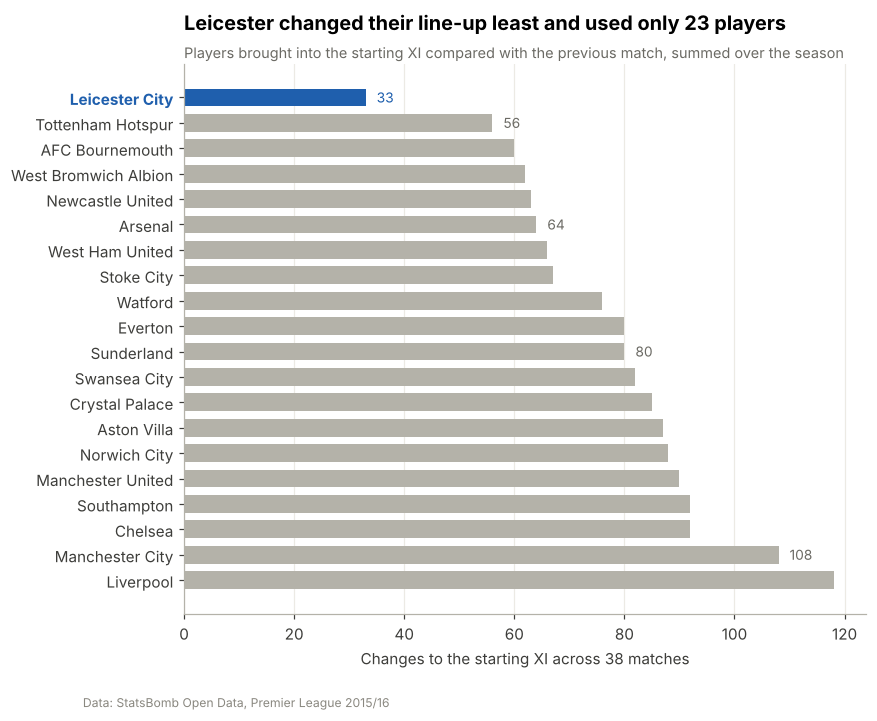

In [18]:
s = stability.sort_values("xi_changes", ascending=False)
fig, ax = plt.subplots(figsize=(8, 6.5))
colors = [BLUE if t == LEI else GREY for t in s.index]
ax.barh(s.index, s.xi_changes, color=colors, height=0.7)
for i, (team, v) in enumerate(s.xi_changes.items()):
    if team in [LEI, "Sunderland"] + RIVALS:
        ax.annotate(str(v), (v + 2, i), va="center", fontsize=9, color=BLUE if team == LEI else "#6B6A64")
for lbl in ax.get_yticklabels():
    if lbl.get_text() == LEI:
        lbl.set_color(BLUE); lbl.set_fontweight("bold")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Changes to the starting XI across 38 matches")
ax.set_title(f"Leicester changed their line-up least and used only {stability.loc[LEI, 'players_used']} players", pad=22)
finish(fig, "05_squad_stability", "Players brought into the starting XI compared with the previous match, summed over the season")

## Summary

The numbers behind each statement are printed in the cells above; `docs/results.md` lists them with their evidence.

1. **A top-four team that took title-winning points.** Leicester's chances were worth about 66 expected points, 4th in the league. They took 81, the biggest overperformance in the league (+15).
2. **Attack carried the first half, defence the second.** In matches 1–19 they scored 37 goals from 31.0 xG (including penalties) while conceding in line with xG. In matches 20–38 the attack cooled (31 goals from 35.3 xG), but the defence conceded only **11 goals from 20.2 xG against**, with 11 clean sheets. Over the whole season, non-penalty finishing was on par with xG (57 from 56.1). The real outlier is defence: 10 goals fewer conceded than the chances allowed, the most in the league (next best: 3.5).
3. **They won tight games.** They had 14 one-goal wins (Arsenal had 7, Spurs 6) and only 3 defeats. They also won the most penalties in the league, 13.
4. **A counter-attacking side.** They had the 3rd-lowest possession and the fastest attack in the league. Their median shot came after 3 passes, and 67% of their shots came within 15 seconds of winning the ball. Their non-penalty xG per shot was the best in the league (0.110).
5. **Stars in the right roles.** Vardy (24 goals) and Mahrez (17) were 1st and 2nd in the league for goals plus assists. Mahrez and Drinkwater supplied 10 of Vardy's goals between them. Kanté made more tackles plus interceptions than any player in the league (274).
6. **The same XI every week.** Leicester used 23 players, the fewest in the league. They made 33 changes to the starting XI all season (Spurs, next fewest, made 56), and their best 11 played 86% of the minutes.

**Limitation:** xG treats every shot as independent and ignores game state. A team leading 1-0 that sits deep concedes many low-quality shots, and keeping them out is partly skill (blocks, goalkeeping) and partly luck. The data alone cannot separate the two, and goalkeeper-specific models (post-shot xG) aren't in this dataset.